C:\Users\Htrieu\AppData\Local\Temp\ipykernel_16984\3351573459.py:24: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query,conn)


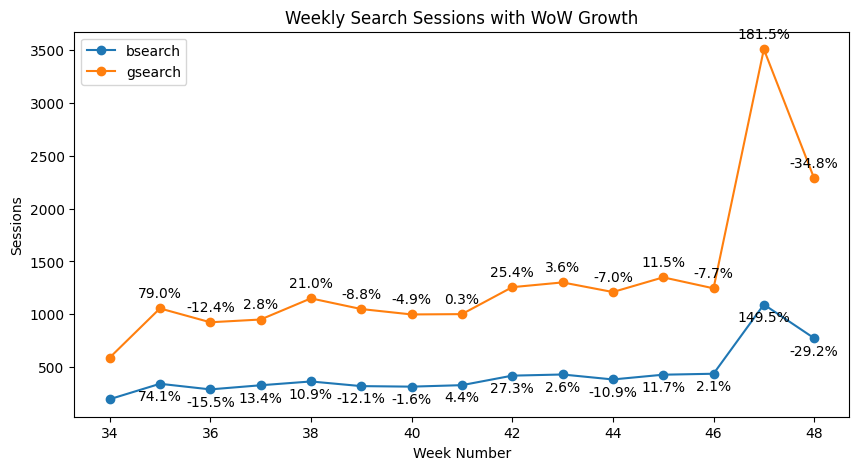

In [ ]:
import mysql.connector
import pandas as pd
import matplotlib.pyplot as plt

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="Hoangtrieu1409",
    database="mavenfuzzyfactory"
)

cursor = conn.cursor()

query = """
SELECT YEARWEEK(created_at) AS 'WEEKS',
		MIN(created_at) AS start_date,
		COUNT(DISTINCT CASE WHEN lower(UTM_source) LIKE 'bsearch' AND lower(UTM_campaign) LIKE 'nonbrand' THEN website_session_id END) AS bsearch_n_session,
		COUNT(DISTINCT CASE WHEN lower(UTM_source) LIKE 'gsearch' AND lower(UTM_campaign) LIKE 'nonbrand' THEN website_session_id END) AS gsearch_n_session FROM website_sessions
        WHERE created_at BETWEEN '2012-08-22' AND '2012-11-29'
        GROUP BY 1
        ORDER BY 1 ASC;
"""

df = pd.read_sql(query,conn)
df["pct_change"] = (
    (df["gsearch_n_session"] - df["bsearch_n_session"]) /
    df["bsearch_n_session"]
)

df["week_num"] = df["WEEKS"].astype(str).str[-2:].astype(int)
import matplotlib.pyplot as plt

df["bsearch_wow"] = df["bsearch_n_session"].pct_change()
df["gsearch_wow"] = df["gsearch_n_session"].pct_change()

plt.figure(figsize=(10,5))

plt.plot(df["week_num"],
         df["bsearch_n_session"],
         marker='o',
         label="bsearch")

plt.plot(df["week_num"],
         df["gsearch_n_session"],
         marker='o',
         label="gsearch")

for i in range(1, len(df)):


    plt.annotate(
        f'{df["gsearch_wow"][i]:.1%}',
        (df["week_num"][i], df["gsearch_n_session"][i]),
        textcoords="offset points",
        xytext=(0,8),
        ha='center'
    )


    plt.annotate(
        f'{df["bsearch_wow"][i]:.1%}',
        (df["week_num"][i], df["bsearch_n_session"][i]),
        textcoords="offset points",
        xytext=(0,-12),
        ha='center'
    )


plt.xlabel("Week Number")
plt.ylabel("Sessions")
plt.title("Weekly Search Sessions with WoW Growth")
plt.legend()

plt.show()